# Week 3 Task 2: Explainability, Error Analysis & Cost-Sensitive Tuning
**Project:** Telco Customer Churn Prediction & Retention Optimization  
**Deliverables:**
1. SHAP global & local interpretability (Bar, Beeswarm, Waterfall plots)
2. Segment Error Analysis answering: *Does the model miss long-tenure high-value churners?*
3. Cost-Sensitive Threshold Tuning tying retention offer cost ($35) vs CLV lost
4. Formal reports: SHAP Report, Model Card, and Error Analysis Writeup


In [1]:
import os
import sys
sys.path.insert(0, os.path.abspath(".."))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import shap

from src.features import prepare_train_test_data
from src.explain import (
    generate_shap_plots,
    perform_segment_error_analysis,
    optimize_cost_sensitive_threshold,
)

%matplotlib inline
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")


C:\Users\kjuge\Documents\jugendrakashyap\AI-ML-Project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load Champion Model & Test Data
Loading serialized `models/best_model.joblib` and holdout test set.


In [2]:
model = joblib.load("../models/best_model.joblib")
metadata = joblib.load("../models/model_metadata.joblib")
data = prepare_train_test_data(filepath="../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

X_test = data["X_test"]
y_test = data["y_test"]
feature_names = data["feature_names"]
df_test_raw = data["df_test_raw"]

print(f"Loaded Champion Model: {metadata['best_model_name']}")
print(f"Test samples: {X_test.shape[0]} | Features: {len(feature_names)}")


Loaded Champion Model: XGBoost (Tuned)
Test samples: 1409 | Features: 34


## 2. SHAP Global Feature Importance
Computing Shapley Additive Explanations using `TreeExplainer`.


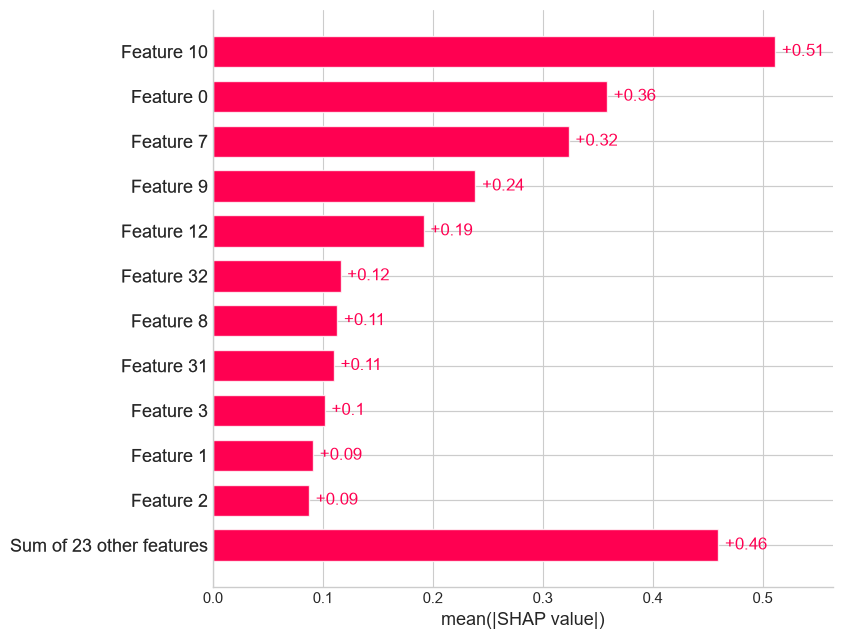

In [3]:
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test)

# Display SHAP summary bar chart
plt.figure(figsize=(10, 6))
shap.plots.bar(shap_values, max_display=12)


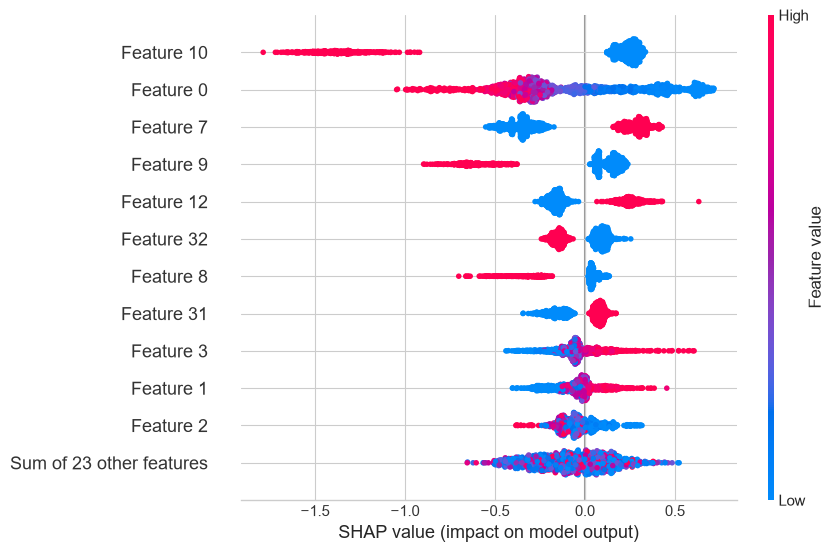

In [4]:
# Display SHAP beeswarm plot
plt.figure(figsize=(11, 7))
shap.plots.beeswarm(shap_values, max_display=12)


## 3. Individual Customer Waterfall Explanations
Comparing a high-risk churner against a loyal retained subscriber.


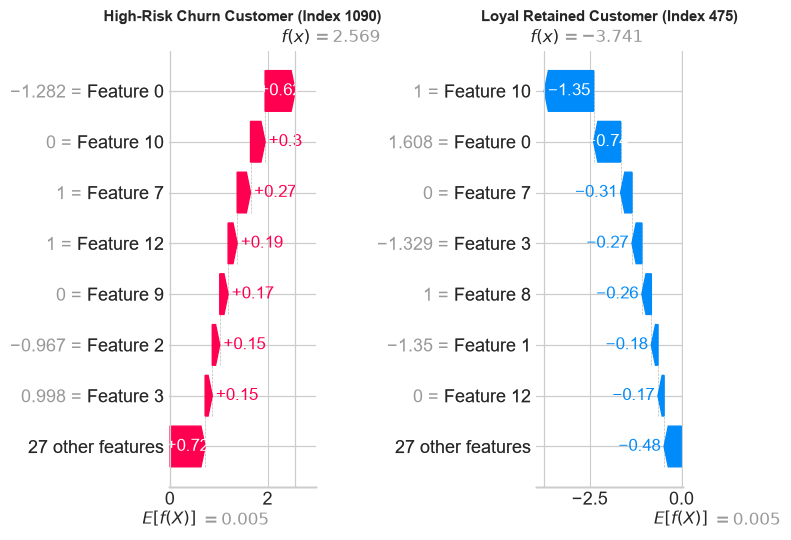

In [5]:
# Identify high-risk and low-risk indices
if len(shap_values.shape) == 3:
    vals = shap_values.values[:, :, 1]
else:
    vals = shap_values.values

high_idx = int(np.argmax(vals.sum(axis=1)))
low_idx = int(np.argmin(vals.sum(axis=1)))

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
plt.sca(axes[0])
shap.plots.waterfall(shap_values[high_idx], max_display=8, show=False)
axes[0].set_title(f"High-Risk Churn Customer (Index {high_idx})", fontsize=11, fontweight="bold")

plt.sca(axes[1])
shap.plots.waterfall(shap_values[low_idx], max_display=8, show=False)
axes[1].set_title(f"Loyal Retained Customer (Index {low_idx})", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()


## 4. Segment Error Analysis: High-Value Long-Tenure Churners
Addressing the CFO's core retention question:
*Does the model miss long-tenure high-value churners — the costliest false negatives?*


In [6]:
error_results = perform_segment_error_analysis(
    model, X_test, y_test, df_test_raw, output_dir="../reports/figures"
)
lthv = error_results["lthv_stats"]
clv_summary = error_results["clv_summary"]

print(f"High-Value Long-Tenure Churners (tenure > 24m, MonthlyCharges >= $70):")
print(f" - Total in Cohort:         {lthv['total_churners']}")
print(f" - Caught (True Positives): {lthv['caught_tp']} ({lthv['recall']*100:.1f}%)")
print(f" - Missed (False Negatives):{lthv['missed_fn']}")
print(f" - CLV Value Protected:     ${lthv['clv_saved_tp']:,.2f}")
print(f" - CLV Value Lost:          ${lthv['clv_lost_fn']:,.2f}")


C:\Users\kjuge\Documents\jugendrakashyap\AI-ML-Project\src\explain.py:200: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=clv_summary, x="error_type", y="total_clv", palette=palette, edgecolor="black")


High-Value Long-Tenure Churners (tenure > 24m, MonthlyCharges >= $70):
 - Total in Cohort:         85
 - Caught (True Positives): 56 (65.9%)
 - Missed (False Negatives):29
 - CLV Value Protected:     $203,724.70
 - CLV Value Lost:          $153,045.80


In [7]:
# Tenure segment error breakdown table
error_results["tenure_breakdown"]


error_type,False Negative (FN),False Positive (FP),True Negative (TN),True Positive (TP),Total_Actual_Churn,Recall
tenure_bucket,,,,,,
0-12,21,137,97,194,215,0.902326
13-24,8,61,85,52,60,0.866667
25-36,8,30,93,32,40,0.800000
37-48,12,25,92,12,24,0.500000
49-60,11,23,132,8,19,0.421053
61-72,11,7,253,5,16,0.312500


## 5. Cost-Sensitive Threshold Tuning & Retention Economics
Evaluating net business profit across thresholds:
- Retention Offer Cost: $35/targeted customer
- Intervention Save Rate: 45%
- Preserved Revenue: 12 months $	imes$ Monthly Charges


In [8]:
df_cost, cost_metrics = optimize_cost_sensitive_threshold(
    model, X_test, y_test, df_test_raw, output_dir="../reports/figures"
)

print(f"Optimal Threshold:              T* = {cost_metrics['optimal_threshold']:.2f}")
print(f"Optimal Net Retention Savings:  ${cost_metrics['optimal_net_savings']:,.2f}")
print(f"Default (T=0.50) Net Savings:   ${cost_metrics['default_net_savings']:,.2f}")
print(f"Profit Uplift Over Default:     +${cost_metrics['incremental_gain_over_default']:,.2f}")
print(f"Churn Recall at T*:             {cost_metrics['optimal_recall']*100:.1f}%")
print(f"Customers Targeted at T*:       {cost_metrics['optimal_targeted']}")


Saved threshold optimization plot to ../reports/figures\cost_sensitive_threshold_curve.png
Optimal Threshold:              T* = 0.30
Optimal Net Retention Savings:  $110,156.16
Default (T=0.50) Net Savings:   $100,951.93
Profit Uplift Over Default:     +$9,204.23
Churn Recall at T*:             92.5%
Customers Targeted at T*:       804


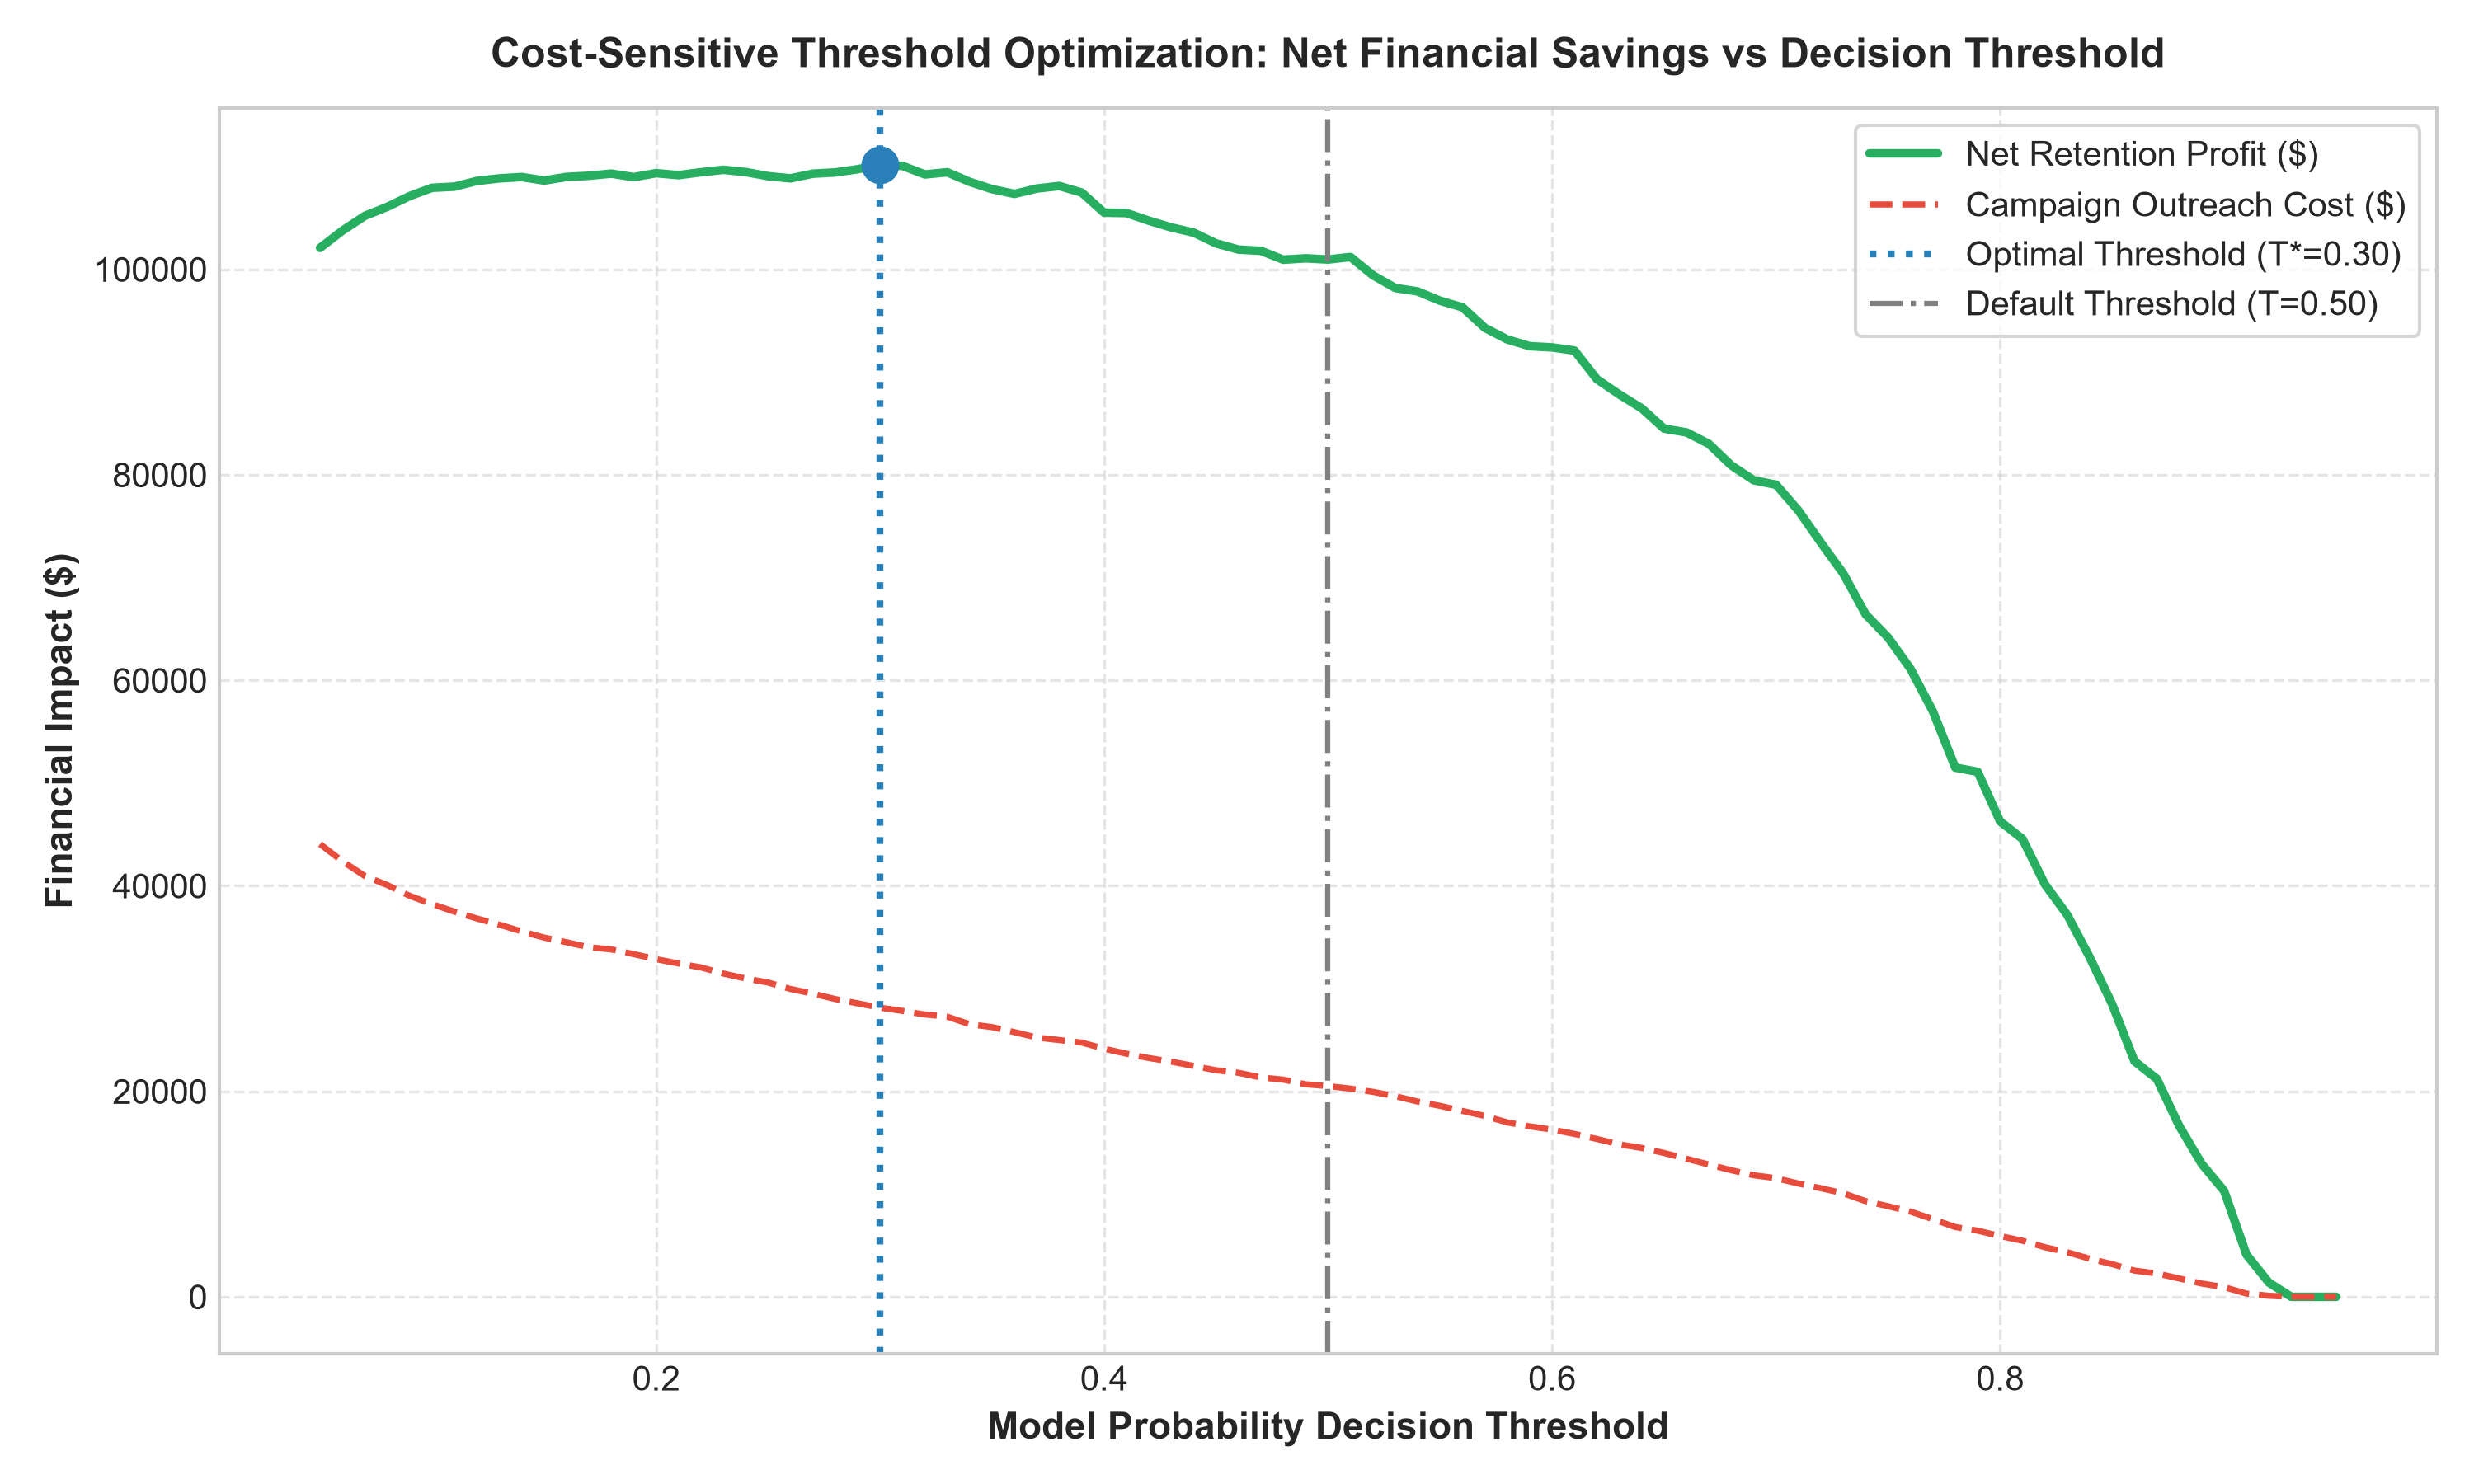

In [9]:
# Display generated figures
from IPython.display import Image, display

display(Image(filename="../reports/figures/cost_sensitive_threshold_curve.png"))


## 6. Deliverable Documentation Links
All formal audit documents have been generated and saved:
- [`reports/shap_report.md`](../reports/shap_report.md)
- [`reports/model_card.md`](../reports/model_card.md)
- [`reports/error_analysis_writeup.md`](../reports/error_analysis_writeup.md)
